<div align="center">

**Regularización en Finanzas**

</div>

# Regresión Regularizada

## Introducción

Los modelos de regresión lineal con muchas variables independientes pueden llevar a **coeficientes pobremente determinados**, causando que el modelo se ajuste extremadamente bien a los datos de entrenamiento pero **muy mal a los datos de prueba**. Este fenómeno se conoce como **sobreajuste (overfitting)** o **alta varianza**.

La **regularización** es una técnica popular para controlar el sobreajuste. Consiste en agregar un **término de penalización** a la función de error o pérdida. El propósito de este término es **desalentar que los coeficientes alcancen valores grandes**.

La regularización es un **mecanismo de penalización** que aplica **contracción (shrinkage)** a los parámetros del modelo, impulsándolos hacia cero. El objetivo es construir un modelo con:
- Mayor precisión predictiva
- Mejor interpretabilidad

## Ventajas de la Regresión Regularizada

La regresión regularizada tiene dos ventajas principales sobre la regresión lineal básica:

### 1. Precisión predictiva

- El sobreajuste significa que el modelo rinde mejor en los datos de entrenamiento pero **falla al generalizar** a datos de prueba no vistos.
- Un modelo con demasiados parámetros puede ajustar **ruido específico** de los datos de entrenamiento.
- Al contraer o establecer coeficientes en cero, hay un **trade-off**: sacrificar la capacidad de ajustar modelos complejos (lo que lleva a mayor sesgo) a cambio de un modelo más generalizable (resultando en menor varianza).

### 2. Interpretación

- Un gran número de predictores puede complicar la interpretación o comunicación de los resultados.
- La regularización hace preferible sacrificar algo de detalle para limitar el modelo a un **subconjunto más pequeño de parámetros** que tienen los efectos más fuertes.

## Formas de Regularizar un Modelo de Regresión Lineal

Las formas comunes de regularizar un modelo de regresión lineal son:

1. **Regulación L1 o Regresión Lasso**
2. **Regulación L2 o Regresión Ridge**
3. **Elastic Net** (combinación de L1 y L2)

## Regulación L1 o Regresión Lasso

La regresión **Lasso** realiza regularización L1 añadiendo un factor de la **suma del valor absoluto de los coeficientes** a la función de costo (Suma de Cuadrados Residuales, RSS) de la regresión lineal.

### Función de Costo - Lasso

$$\text{CostFunction} = RSS + \lambda \sum_{j=1}^{p} |\beta_j|$$

Donde:
- **RSS** = Suma de Cuadrados Residuales
- **$\lambda$** (lambda) = Parámetro de regularización
- **$\sum_{j=1}^{p} |\beta_j|$** = Suma de los valores absolutos de los coeficientes $\beta$ desde $j=1$ hasta $p$

### Impacto y Beneficios de la Regularización L1

- La regularización L1 puede hacer que **algunos coeficientes sean exactamente cero**.
- Cuando un coeficiente es cero, significa que esa característica es **completamente descartada** para la evaluación de la salida.
- Un valor **mayor de $\lambda$** resulta en más características siendo contraídas a cero.
- Este proceso puede **eliminar algunas características completamente**, proporcionando un subconjunto de predictores y reduciendo así la complejidad del modelo.
- La regresión Lasso no solo ayuda a reducir el sobreajuste sino que también facilita la **selección de características (feature selection)**.
- Los predictores cuyos coeficientes no se contraen hacia cero se consideran **importantes**.
- Por tanto, la regularización L1 facilita la **selección dispersa (sparse selection)**.
- El parámetro de regularización **$\lambda$** puede ser controlado por el usuario/modelador.
- Un valor de **$\lambda = 0$** reduce la ecuación a la regresión lineal básica (sin regularización).

## Regulación L2 o Regresión Ridge

La regresión **Ridge** realiza regularización L2 añadiendo un factor de la **suma del cuadrado de los coeficientes** a la función de costo (RSS) de la regresión lineal.

### Función de Costo - Ridge

$$\text{CostFunction} = RSS + \lambda \sum_{j=1}^{p} \beta_j^2$$

Donde:
- **RSS** = Suma de Cuadrados Residuales
- **$\lambda$** (lambda) = Parámetro de regularización
- **$\sum_{j=1}^{p} \beta_j^2$** = Suma de los cuadrados de los coeficientes $\beta$

### Impacto y Beneficios de la Regularización L2

- Ridge impone una **restricción sobre los coeficientes**.
- El término de penalización regulariza los coeficientes: si toman valores grandes, la función de optimización es penalizada.
- **Contrae los coeficientes** y ayuda a reducir la complejidad del modelo.
- La contracción de coeficientes lleva a **menor varianza** y **menores errores**.
- **Diferencia clave con Lasso**: Ridge **reduce la complejidad del modelo pero NO reduce el número de variables**; solo contrae la magnitud de su efecto. Los coeficientes se acercan a cero pero rara vez llegan exactamente a cero.
- Cuando $\lambda$ se acerca a cero, la función de costo se vuelve similar a la regresión lineal estándar.
- Un $\lambda$ más bajo significa menos restricción sobre las características, haciendo que el modelo se parezca más a la regresión lineal.

## Elastic Net

**Elastic Net** combina términos de regularización de **L1 y L2** en una sola función de costo.

### Función de Costo - Elastic Net

$$\text{CostFunction} = RSS + \lambda \left( \frac{1-\alpha}{2} \sum_{j=1}^{p} \beta_j^2 + \alpha \sum_{j=1}^{p} |\beta_j| \right)$$

Donde:
- **$\alpha$** (alpha) = Parámetro que controla la mezcla entre L1 y L2
- **$\alpha = 0$** → Ridge puro (solo L2)
- **$\alpha = 1$** → Lasso puro (solo L1)
- **$0 < \alpha < 1$** → Combinación de ambos

### Ventajas de Elastic Net

- Permite optimizar el valor de $\alpha$ entre 0 y 1 según el problema.
- Puede contraer algunos coeficientes y establecer otros en cero (propiedad de L1/Lasso).
- Útil cuando hay alta correlación entre predictores o cuando se desea tanto contracción como selección de características.

## Importación de Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso, Ridge, ElasticNet, LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

print("Librerías importadas exitosamente")

Librerías importadas exitosamente


## Ejemplo Práctico: Lasso vs Regresión Lineal

Vamos a comparar el comportamiento de Lasso con la regresión lineal estándar. Usaremos un ejemplo con múltiples predictores para ilustrar cómo Lasso realiza selección de características.

In [2]:
# Generar datos simulados: muchas variables, algunas irrelevantes
np.random.seed(42)
n_samples = 100
n_features = 15

# Solo las primeras 3 características son relevantes
X = np.random.randn(n_samples, n_features)
betas_reales = np.zeros(n_features)
betas_reales[:3] = [2.5, 1.5, 0.8]  # Solo 3 coeficientes no nulos

y = X @ betas_reales + np.random.normal(0, 1, n_samples)

# Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Estandarizar (importante para regularización)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Datos generados: 100 muestras, 15 características")
print("Solo 3 características son realmente relevantes (coeficientes no nulos)")

Datos generados: 100 muestras, 15 características
Solo 3 características son realmente relevantes (coeficientes no nulos)


In [4]:
# Comparar Regresión Lineal vs Lasso
lr = LinearRegression()
lasso = Lasso(alpha=0.5)  # alpha es lambda en sklearn

lr.fit(X_train_scaled, y_train)
lasso.fit(X_train_scaled, y_train)

# Coeficientes
print("Coeficientes - Regresión Lineal:")
print(lr.coef_)
print("\nCoeficientes - Lasso (alpha=0.5):")
print(lasso.coef_)
print(f"\nNúmero de coeficientes = 0 en Lasso: {np.sum(lasso.coef_ == 0)} de {n_features}")

Coeficientes - Regresión Lineal:
[ 1.96344117  1.67308034  0.8595744   0.15418504  0.05875789 -0.15703437
 -0.13419978  0.04614446  0.22680276  0.04912192  0.11150545  0.08823233
  0.00205161  0.00598998 -0.0651449 ]

Coeficientes - Lasso (alpha=0.5):
[ 1.60383288  1.26686734  0.48140493  0.          0.         -0.
 -0.          0.          0.         -0.          0.          0.
 -0.          0.         -0.        ]

Número de coeficientes = 0 en Lasso: 12 de 15


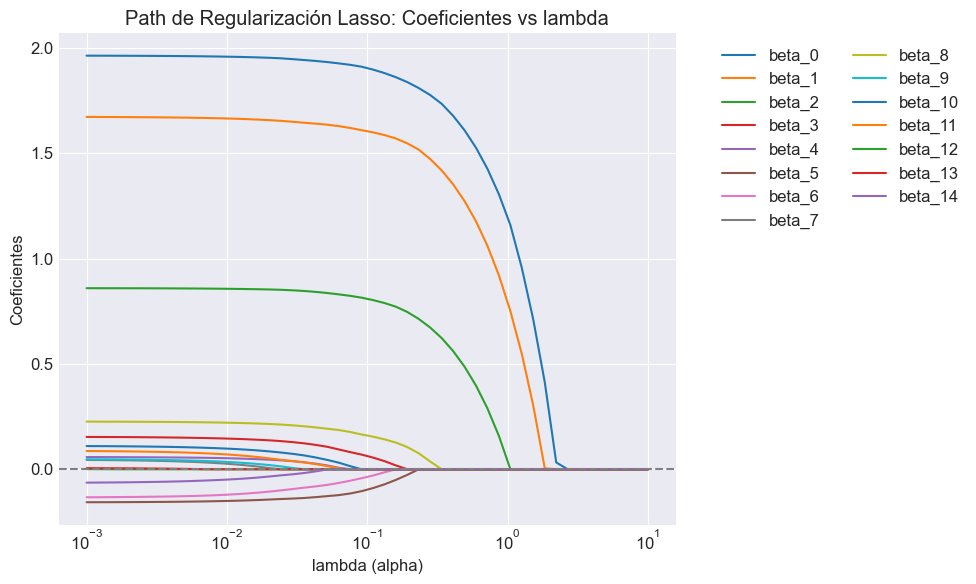

A mayor lambda, más coeficientes se contraen a cero (selección de características)


In [10]:
# Efecto de lambda en la selección de características
alphas = np.logspace(-3, 1, 50)
coefs_lasso = []

for alpha in alphas:
    lasso_temp = Lasso(alpha=alpha)
    lasso_temp.fit(X_train_scaled, y_train)
    coefs_lasso.append(lasso_temp.coef_)

coefs_lasso = np.array(coefs_lasso)

# Visualizar el path de regularización
plt.figure(figsize=(10, 6))
for i in range(n_features):
    plt.plot(alphas, coefs_lasso[:, i], label=f'beta_{i}')
plt.xscale('log')
plt.xlabel('lambda (alpha)')
plt.ylabel('Coeficientes')
plt.title('Path de Regularización Lasso: Coeficientes vs lambda')
plt.axhline(y=0, color='gray', linestyle='--')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)
plt.tight_layout()
plt.show()

print("A mayor lambda, más coeficientes se contraen a cero (selección de características)")

## Ridge: Path de Regularización vs Lasso

A diferencia de Lasso, Ridge contrae los coeficientes pero **nunca los lleva exactamente a cero**. Todos los predictores permanecen en el modelo.

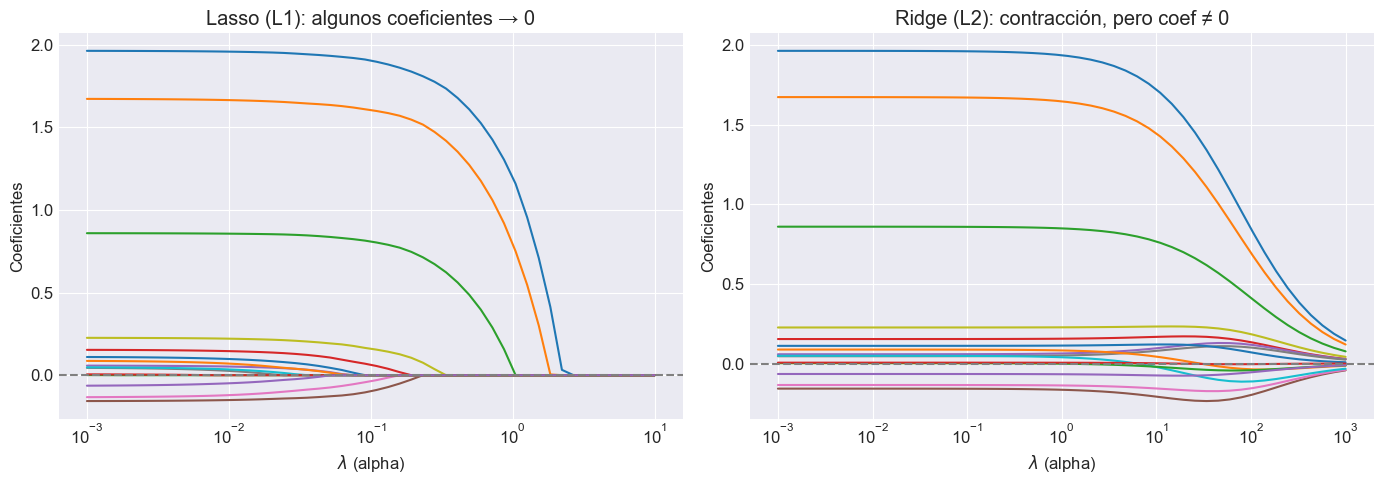

In [11]:
# Path de regularización Ridge
alphas_ridge = np.logspace(-3, 3, 50)
coefs_ridge = []

for alpha in alphas_ridge:
    ridge_temp = Ridge(alpha=alpha)
    ridge_temp.fit(X_train_scaled, y_train)
    coefs_ridge.append(ridge_temp.coef_)

coefs_ridge = np.array(coefs_ridge)

# Comparar Lasso vs Ridge
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Lasso
for i in range(n_features):
    axes[0].plot(alphas, coefs_lasso[:, i])
axes[0].set_xscale('log')
axes[0].set_xlabel('$\\lambda$ (alpha)')
axes[0].set_ylabel('Coeficientes')
axes[0].set_title('Lasso (L1): algunos coeficientes → 0')
axes[0].axhline(y=0, color='gray', linestyle='--')

# Ridge
for i in range(n_features):
    axes[1].plot(alphas_ridge, coefs_ridge[:, i])
axes[1].set_xscale('log')
axes[1].set_xlabel('$\\lambda$ (alpha)')
axes[1].set_ylabel('Coeficientes')
axes[1].set_title('Ridge (L2): contracción, pero coef ≠ 0')
axes[1].axhline(y=0, color='gray', linestyle='--')

plt.tight_layout()
plt.show()

## Comparación: Lasso, Ridge y Elastic Net

Implementación con `sklearn`:

In [12]:
# Implementación con sklearn
lasso_model = Lasso(alpha=0.5)
ridge_model = Ridge(alpha=0.5)
elastic_model = ElasticNet(alpha=0.5, l1_ratio=0.5)  # l1_ratio=α: 0=Ridge, 1=Lasso

lasso_model.fit(X_train_scaled, y_train)
ridge_model.fit(X_train_scaled, y_train)
elastic_model.fit(X_train_scaled, y_train)

# Resumen comparativo
comparison = pd.DataFrame({
    'Característica': [f'$\\beta_{i}$' for i in range(n_features)],
    'Lasso': lasso_model.coef_,
    'Ridge': ridge_model.coef_,
    'Elastic Net': elastic_model.coef_
})
print("Coeficientes estimados:")
print(comparison.to_string(index=False))
print(f"\nCoeficientes = 0: Lasso={np.sum(lasso_model.coef_==0)}, Ridge={np.sum(ridge_model.coef_==0)}, Elastic Net={np.sum(elastic_model.coef_==0)}")

Coeficientes estimados:
Característica     Lasso     Ridge  Elastic Net
     $\beta_0$  1.603833  1.949403     1.459925
     $\beta_1$  1.266867  1.659510     1.203463
     $\beta_2$  0.481405  0.854170     0.592970
     $\beta_3$  0.000000  0.155289     0.000000
     $\beta_4$  0.000000  0.061311     0.000000
     $\beta_5$ -0.000000 -0.160718    -0.054897
     $\beta_6$ -0.000000 -0.135670    -0.016859
     $\beta_7$  0.000000  0.048516     0.000000
     $\beta_8$  0.000000  0.227313     0.101160
     $\beta_9$ -0.000000  0.044429    -0.000000
    $\beta_10$  0.000000  0.112377     0.000000
    $\beta_11$  0.000000  0.085400    -0.000000
    $\beta_12$ -0.000000  0.000553    -0.000000
    $\beta_13$  0.000000  0.005781     0.000000
    $\beta_14$ -0.000000 -0.065942    -0.000000

Coeficientes = 0: Lasso=12, Ridge=0, Elastic Net=9


## Ejemplo Financiero: Predicción de Retornos

En finanzas, Lasso es útil cuando tenemos muchos factores potenciales (indicadores técnicos, macroeconómicos, etc.) y queremos identificar cuáles realmente importan para predecir retornos o riesgos.

In [13]:
# Simulación: predicción de retornos con múltiples factores
np.random.seed(123)
n = 200
p = 20  # 20 factores potenciales

factores = np.random.randn(n, p)
# Solo 4 factores influyen en los retornos
betas_importantes = np.zeros(p)
betas_importantes[[0, 5, 10, 15]] = [0.3, -0.2, 0.15, 0.25]

retornos = factores @ betas_importantes + np.random.normal(0, 0.5, n)

X_train, X_test, y_train, y_test = train_test_split(factores, retornos, test_size=0.25, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Lasso con validación cruzada para elegir lambda
from sklearn.linear_model import LassoCV
lasso_cv = LassoCV(cv=5, alphas=np.logspace(-4, 0, 100))
lasso_cv.fit(X_train_s, y_train)

print(f"Lambda óptimo (alpha): {lasso_cv.alpha_:.6f}")
print(f"Factores seleccionados (coef ≠ 0): {np.sum(lasso_cv.coef_ != 0)} de {p}")
print("\nCoeficientes de los factores seleccionados:")
for i in np.where(lasso_cv.coef_ != 0)[0]:
    print(f"  Factor {i}: {lasso_cv.coef_[i]:.4f}")

Lambda óptimo (alpha): 0.055908
Factores seleccionados (coef ≠ 0): 6 de 20

Coeficientes de los factores seleccionados:
  Factor 0: 0.2986
  Factor 5: -0.1067
  Factor 10: 0.1459
  Factor 13: 0.0006
  Factor 15: 0.1917
  Factor 17: 0.0112


## Resumen

- **Regularización**: mecanismo para controlar el sobreajuste mediante penalización de coeficientes grandes.
- **Lasso (L1)**: añade $\lambda \sum |\beta_j|$ a la función de costo. Permite **selección de características** (coeficientes exactamente cero).
- **Ridge (L2)**: añade $\lambda \sum \beta_j^2$ a la función de costo. **Contrae** coeficientes pero no los elimina; reduce varianza sin reducir el número de variables.
- **Elastic Net**: combina L1 y L2 con parámetro $\alpha$; $\alpha=0$ → Ridge, $\alpha=1$ → Lasso.
- **$\lambda$**: controla el trade-off entre sesgo y varianza; mayor $\lambda$ → más contracción.
- **En finanzas**: Lasso para identificar factores relevantes; Ridge cuando hay predictores correlacionados; Elastic Net como enfoque intermedio.